# Practicing with the Functional API and the Layer class

Assignment from *Programming Exercises Chapter 14*, Stijn Lievens and Simon De Gheselle (June 26, 2026). Each part has its own empty code cell. Add written answers beneath the relevant cell. No solutions are included.

## Setup
Add your imports and setup here.

## 2.1 Implementing a Residual Unit

Study the supplied `ResidualUnit` implementation (Figure 1, book page 515). It subclasses `keras.layers.Layer` because it will be used inside a larger model.

### Supplied reference implementation (Figure 1)

```python
from functools import partial
DefaultConv2D = partial (keras.layers.Conv2D , kernel_size =3, strides =1,
padding = "same ", kernel_initializer = "he_normal ",
use_bias =False)
class ResidualUnit (keras.layers.Layer):
def __init__ (self , filters , strides =1, activation = "relu ", ** kwargs):
super (). __init__ (** kwargs)
self. activation = keras. activations .get( activation )
self. main_layers = [
DefaultConv2D (filters , strides = strides ),
keras.layers. BatchNormalization (),
self.activation ,
DefaultConv2D ( filters ),
keras.layers. BatchNormalization ()
]
self. skip_layers = []
if strides > 1:
self. skip_layers = [
DefaultConv2D (filters , kernel_size =1, strides = strides ),
keras.layers. BatchNormalization ()
]
def call(self , inputs):
Z = inputs
for layer in self. main_layers :
Z = layer(Z)
skip_Z = inputs
for layer in self. skip_layers :
skip_Z = layer(skip_Z)
return self. activation (Z + skip_Z)

```

## 2.1.1 Rewrite ResidualUnit using the Functional API

Complete `residual_unit(input_, filters, strides=1, activation="relu")` so it performs the same computation as the supplied class. Supplied opening:
```python
def residual_unit(input_, filters, strides=1, activation="relu"):
    activation_layer = keras.activations.get(activation)
    main = DefaultConv2D(filters, strides=strides)(input_)
    # YOUR CODE HERE
```

Complete Figure 2: create `model1` using the class and `model2` using your function, with `TEST_SHAPE = (128, 128, 50)` and 50 filters. Compare summaries and parameter counts.

Create a random input tensor with batch size one. Call both models and check and explain their output shapes.

### Part 4

Copy weights using `model1.set_weights(model2.get_weights())`. Combine `keras.ops.isclose` and `keras.ops.all` to verify equal outputs for the same input.

## 2.1.2 Write a method that returns a Model

Implement `residual_unit_model(input_shape, filters, strides=1, activation="relu", name=None) -> keras.Model`. Wrap the same computation in a model and pass `name` when constructing it. The returned model should be usable inside a larger model.

Create `model3 = residual_unit_model(TEST_SHAPE, filters=50)` and check that it behaves identically to the previous models after matching weights.

Compare and contrast the summaries of `model1`, `model2`, and `model3`.

## 2.2 Build a Convolutional Layer from Scratch

Subclass `keras.layers.Layer` to create `MyConv2D`. Its constructor accepts `filters: int`, `kernel_size: int`, `activation: str`, and `**kwargs`. The kernel is square; other options are fixed. See https://keras.io/api/layers/base_layer/.

Implement `__init__`: call the superclass, store the three parameters, and convert the activation string to an activation object.

Implement `build(batch_input_shape)`: the shape includes a batch dimension. Add kernel and bias weights with `self.add_weight`. Initialize the kernel with `he_normal` and bias with zeros. Study `keras.ops.conv` to determine the required weight shapes.

### Part 4

Implement `call(inputs)`: compute the convolution using `keras.ops.conv`, add the bias, and apply the activation.

### Part 5

Compare your layer with a built-in `Conv2D` layer. Copy weights between the layers and verify identical results.

## Original figures and starter-code reference
The assignment above is editable Markdown. These original pages preserve diagram labels and the formatting of supplied code.

### Assignment — source page 8

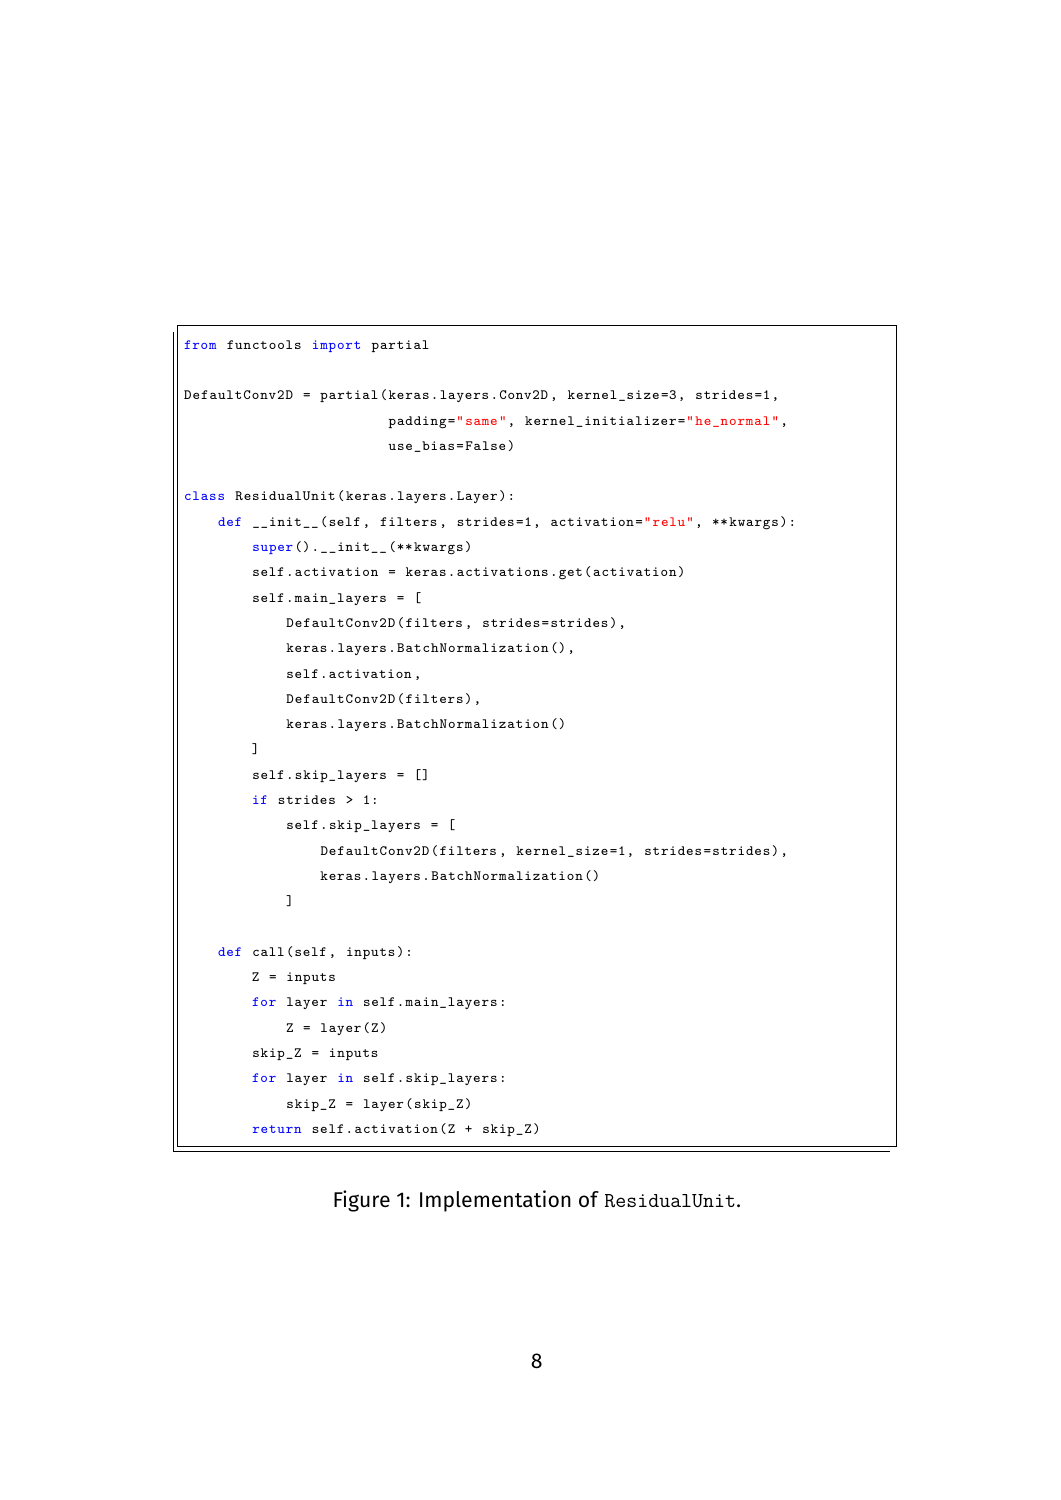

### Assignment — source page 9

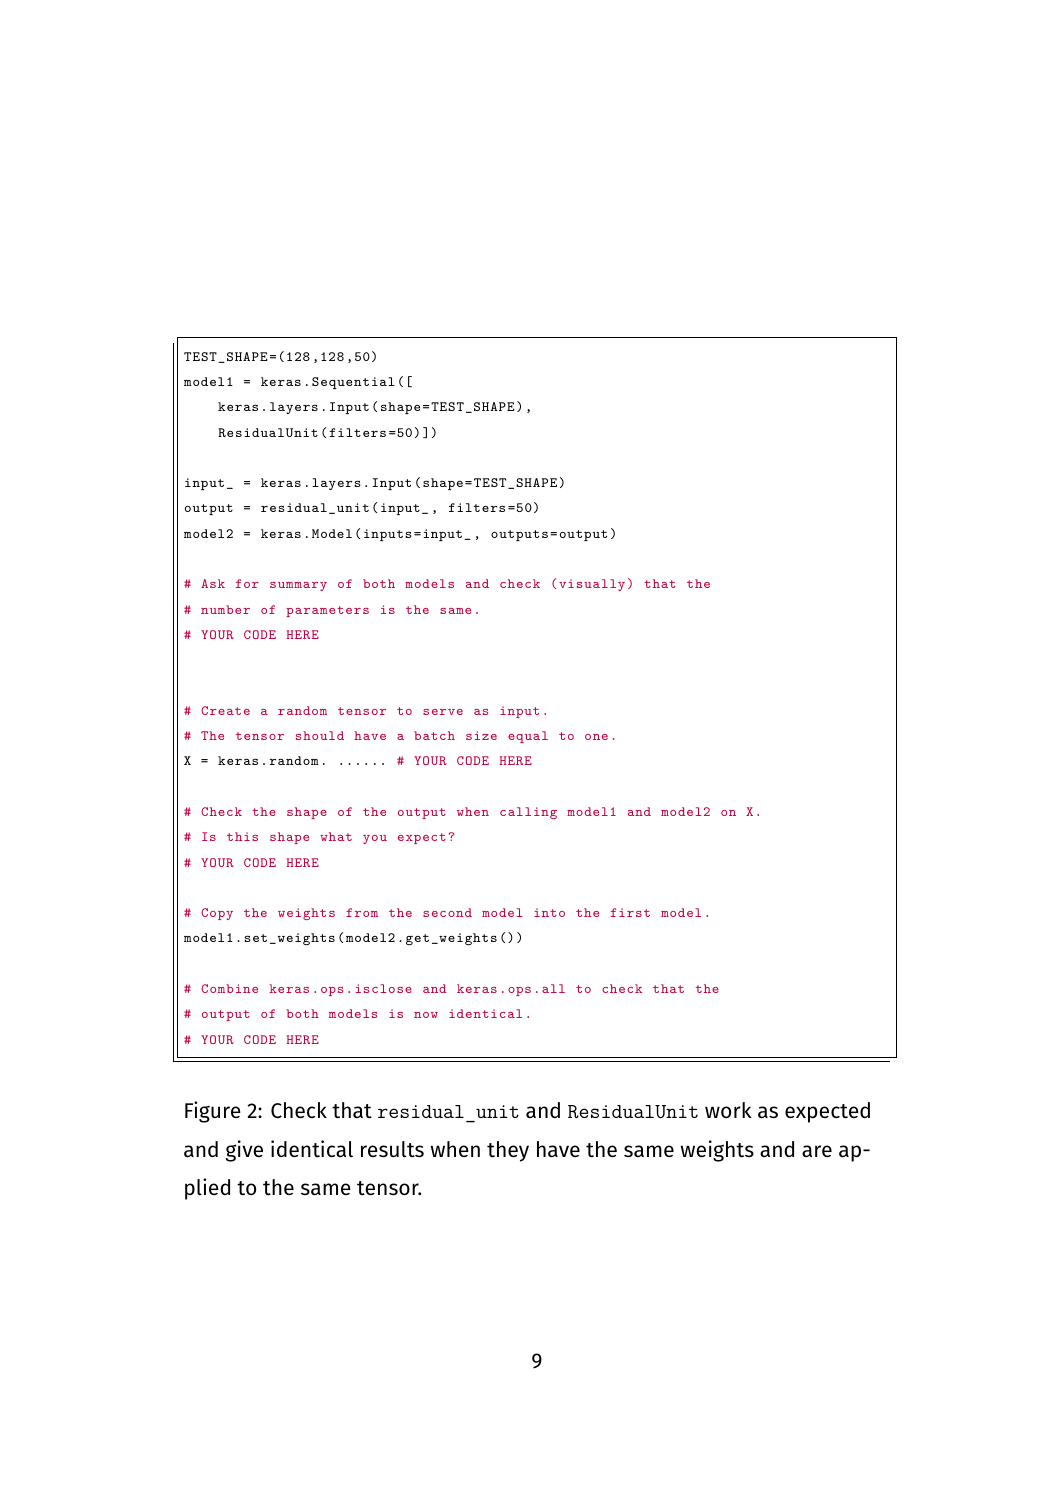

### Assignment — source page 11

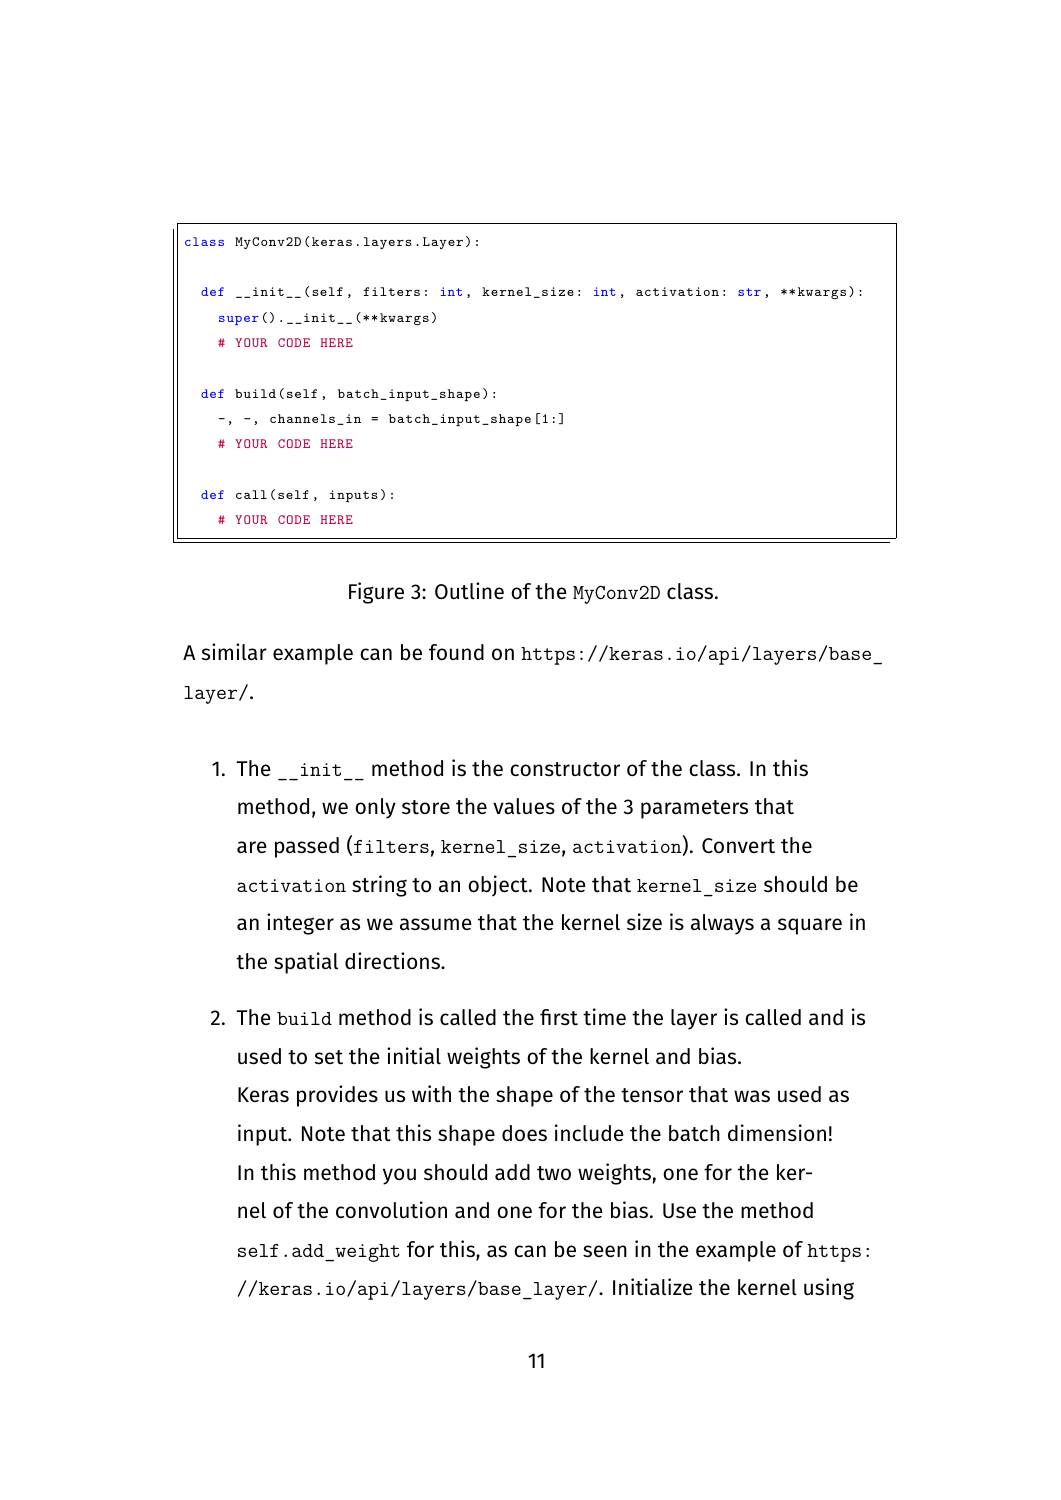